In [1]:
import pandas as pd

df = pd.read_csv("../data/traffic_history.csv")

df.head()

,timestamp,source_region,destination_region,traffic_volume_gb
0,2026-09-01 00:00:00,AWS_HYD,AWS_MUM,343.67
1,2026-09-01 00:00:00,AWS_HYD,AWS_SIN,161.23
2,2026-09-01 00:00:00,AWS_HYD,AZURE_CIN,66.18
3,2026-09-01 00:00:00,AWS_HYD,AZURE_SEA,93.81
4,2026-09-01 00:00:00,AWS_HYD,AZURE_SIN,26.80


In [6]:
print(df.shape)
print(df.columns.tolist())
print(df.dtypes)

(51840, 4)
['timestamp', 'source_region', 'destination_region', 'traffic_volume_gb']
timestamp                 str
source_region             str
destination_region        str
traffic_volume_gb     float64
dtype: object


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 51840 entries, 0 to 51839
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   timestamp           51840 non-null  str    
 1   source_region       51840 non-null  str    
 2   destination_region  51840 non-null  str    
 3   traffic_volume_gb   51840 non-null  float64
dtypes: float64(1), str(3)
memory usage: 1.6 MB


In [8]:
df.describe()

,traffic_volume_gb
count,51840.000000
mean,96.601389
std,97.978674
min,9.440000
25%,34.260000
50%,60.390000
75%,126.872500
max,1007.620000


In [9]:
df["timestamp"] = pd.to_datetime(df["timestamp"])

df.dtypes

timestamp             datetime64[us]
source_region                    str
destination_region               str
traffic_volume_gb            float64
dtype: object

In [10]:
df.head()

,timestamp,source_region,destination_region,traffic_volume_gb
0,2026-09-01,AWS_HYD,AWS_MUM,343.67
1,2026-09-01,AWS_HYD,AWS_SIN,161.23
2,2026-09-01,AWS_HYD,AZURE_CIN,66.18
3,2026-09-01,AWS_HYD,AZURE_SEA,93.81
4,2026-09-01,AWS_HYD,AZURE_SIN,26.80


In [11]:
route_counts = (
    df.groupby(
        ["source_region", "destination_region"]
    )
    .size()
    .reset_index(name="records")
    .sort_values("records", ascending=False)
)

route_counts

,source_region,destination_region,records
0,AWS_HYD,AWS_MUM,720
1,AWS_HYD,AWS_SIN,720
2,AWS_HYD,AZURE_CIN,720
3,AWS_HYD,AZURE_SEA,720
4,AWS_HYD,AZURE_SIN,720
...,...,...,...
67,GCP_SIN,AZURE_CIN,720
68,GCP_SIN,AZURE_SEA,720
69,GCP_SIN,AZURE_SIN,720
70,GCP_SIN,GCP_DEL,720


In [12]:
print("Total routes:", len(route_counts))
print("Records per route:")
print(route_counts["records"].value_counts().sort_index())

Total routes: 72
Records per route:
records
720    72
Name: count, dtype: int64


In [13]:
print(df["timestamp"].nunique())
print(df["timestamp"].min())
print(df["timestamp"].max())

720
2026-09-01 00:00:00
2026-09-30 23:00:00


In [14]:
SOURCE = "AWS_HYD"
DESTINATION = "AWS_MUM"

route_df = df[
    (df["source_region"] == SOURCE) &
    (df["destination_region"] == DESTINATION)
].copy()

route_df = route_df.sort_values("timestamp")

print(route_df.shape)
print(route_df.head())

(720, 4)
              timestamp source_region destination_region  traffic_volume_gb
0   2026-09-01 00:00:00       AWS_HYD            AWS_MUM             343.67
72  2026-09-01 01:00:00       AWS_HYD            AWS_MUM             305.20
144 2026-09-01 02:00:00       AWS_HYD            AWS_MUM             296.89
216 2026-09-01 03:00:00       AWS_HYD            AWS_MUM             296.49
288 2026-09-01 04:00:00       AWS_HYD            AWS_MUM             292.83


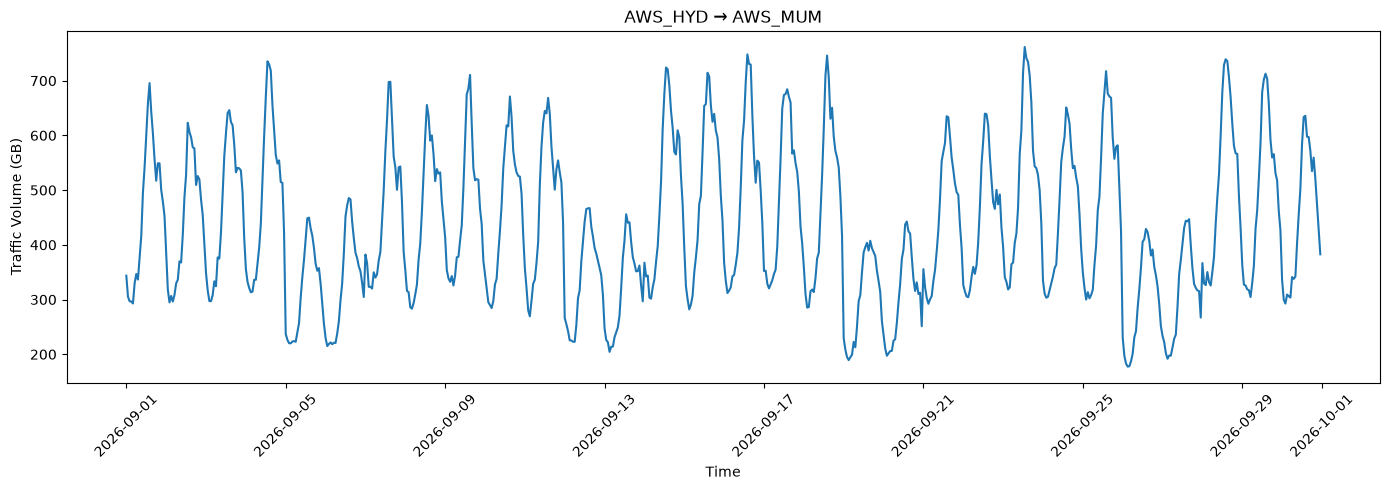

In [16]:
import matplotlib.pyplot as plt
plt.figure(figsize=(14, 5))

plt.plot(
    route_df["timestamp"],
    route_df["traffic_volume_gb"]
)

plt.xlabel("Time")
plt.ylabel("Traffic Volume (GB)")
plt.title(f"{SOURCE} → {DESTINATION}")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [17]:
route_df["traffic_volume_gb"].describe()

count    720.000000
mean     433.435514
std      140.624036
min      177.510000
25%      324.000000
50%      404.740000
75%      544.995000
max      761.570000
Name: traffic_volume_gb, dtype: float64

In [18]:
print(
    route_df.groupby(
        route_df["timestamp"].dt.hour
    )["traffic_volume_gb"].mean()
)

timestamp
0     328.816333
1     298.108667
2     283.391000
3     278.916333
4     282.356667
5     292.826000
6     306.258333
7     324.959000
8     353.053000
9     396.325000
10    450.168000
11    511.273000
12    565.308333
13    606.063000
14    620.930667
15    607.980000
16    578.171667
17    538.749000
18    503.787667
19    492.628000
20    491.196667
21    473.437667
22    436.037000
23    381.711333
Name: traffic_volume_gb, dtype: float64


In [19]:
print(
    route_df.groupby(
        route_df["timestamp"].dt.dayofweek
    )["traffic_volume_gb"].mean()
)

timestamp
0    484.512500
1    471.698833
2    473.671250
3    469.279583
4    485.607292
5    314.763021
6    314.891354
Name: traffic_volume_gb, dtype: float64


In [20]:
# Sort by route and time.
# This is important because an LSTM must receive observations in chronological order.
df = df.sort_values(
    ["source_region", "destination_region", "timestamp"]
).reset_index(drop=True)

# TIME FEATURES

# Hour of the day: 0 = midnight, 23 = 11 PM
# This helps the model learn daily traffic patterns.
df["hour"] = df["timestamp"].dt.hour

# Day of the week: Monday = 0, Sunday = 6
# This helps the model learn weekday/weekend behavior.
df["day_of_week"] = df["timestamp"].dt.dayofweek

# Day number within the month.
# This gives the model a sense of where it is in the 30-day period.
df["day"] = df["timestamp"].dt.day


print(df.head())
print(df.shape)

            timestamp source_region destination_region  traffic_volume_gb  \
0 2026-09-01 00:00:00       AWS_HYD            AWS_MUM             343.67   
1 2026-09-01 01:00:00       AWS_HYD            AWS_MUM             305.20   
2 2026-09-01 02:00:00       AWS_HYD            AWS_MUM             296.89   
3 2026-09-01 03:00:00       AWS_HYD            AWS_MUM             296.49   
4 2026-09-01 04:00:00       AWS_HYD            AWS_MUM             292.83   

   hour  day_of_week  day  
0     0            1    1  
1     1            1    1  
2     2            1    1  
3     3            1    1  
4     4            1    1  
(51840, 7)


In [21]:
print(df[[
    "timestamp",
    "source_region",
    "destination_region",
    "traffic_volume_gb",
    "hour",
    "day_of_week",
    "day"
]].head(10))

            timestamp source_region destination_region  traffic_volume_gb  \
0 2026-09-01 00:00:00       AWS_HYD            AWS_MUM             343.67   
1 2026-09-01 01:00:00       AWS_HYD            AWS_MUM             305.20   
2 2026-09-01 02:00:00       AWS_HYD            AWS_MUM             296.89   
3 2026-09-01 03:00:00       AWS_HYD            AWS_MUM             296.49   
4 2026-09-01 04:00:00       AWS_HYD            AWS_MUM             292.83   
5 2026-09-01 05:00:00       AWS_HYD            AWS_MUM             329.63   
6 2026-09-01 06:00:00       AWS_HYD            AWS_MUM             346.75   
7 2026-09-01 07:00:00       AWS_HYD            AWS_MUM             336.59   
8 2026-09-01 08:00:00       AWS_HYD            AWS_MUM             377.24   
9 2026-09-01 09:00:00       AWS_HYD            AWS_MUM             416.22   

   hour  day_of_week  day  
0     0            1    1  
1     1            1    1  
2     2            1    1  
3     3            1    1  
4     4     

In [22]:
# Give every source → destination pair a unique route ID.
# Example: AWS_HYD → AWS_MUM becomes one route category.
df["route_id"] = (
    df["source_region"] + "->" + df["destination_region"]
)

print("Number of routes:", df["route_id"].nunique())
print(df["route_id"].unique())

Number of routes: 72
<StringArray>
[    'AWS_HYD->AWS_MUM',     'AWS_HYD->AWS_SIN',   'AWS_HYD->AZURE_CIN',
   'AWS_HYD->AZURE_SEA',   'AWS_HYD->AZURE_SIN',     'AWS_HYD->GCP_DEL',
     'AWS_HYD->GCP_MUM',     'AWS_HYD->GCP_SIN',     'AWS_MUM->AWS_HYD',
     'AWS_MUM->AWS_SIN',   'AWS_MUM->AZURE_CIN',   'AWS_MUM->AZURE_SEA',
   'AWS_MUM->AZURE_SIN',     'AWS_MUM->GCP_DEL',     'AWS_MUM->GCP_MUM',
     'AWS_MUM->GCP_SIN',     'AWS_SIN->AWS_HYD',     'AWS_SIN->AWS_MUM',
   'AWS_SIN->AZURE_CIN',   'AWS_SIN->AZURE_SEA',   'AWS_SIN->AZURE_SIN',
     'AWS_SIN->GCP_DEL',     'AWS_SIN->GCP_MUM',     'AWS_SIN->GCP_SIN',
   'AZURE_CIN->AWS_HYD',   'AZURE_CIN->AWS_MUM',   'AZURE_CIN->AWS_SIN',
 'AZURE_CIN->AZURE_SEA', 'AZURE_CIN->AZURE_SIN',   'AZURE_CIN->GCP_DEL',
   'AZURE_CIN->GCP_MUM',   'AZURE_CIN->GCP_SIN',   'AZURE_SEA->AWS_HYD',
   'AZURE_SEA->AWS_MUM',   'AZURE_SEA->AWS_SIN', 'AZURE_SEA->AZURE_CIN',
 'AZURE_SEA->AZURE_SIN',   'AZURE_SEA->GCP_DEL',   'AZURE_SEA->GCP_MUM',
   'AZURE_SEA->G

In [23]:
print(
    df.groupby("route_id")
      .size()
      .describe()
)

count     72.0
mean     720.0
std        0.0
min      720.0
25%      720.0
50%      720.0
75%      720.0
max      720.0
dtype: float64


In [25]:
from sklearn.preprocessing import LabelEncoder, MinMaxScaler

# Convert each source → destination pair into a unique numerical ID.
# This lets us tell the model which route each traffic sequence belongs to.
route_encoder = LabelEncoder()

df["route_encoded"] = route_encoder.fit_transform(df["route_id"])

print(df[[
    "route_id",
    "route_encoded"
]].drop_duplicates().head(15))

print("Number of encoded routes:", df["route_encoded"].nunique())

                 route_id  route_encoded
0        AWS_HYD->AWS_MUM              0
720      AWS_HYD->AWS_SIN              1
1440   AWS_HYD->AZURE_CIN              2
2160   AWS_HYD->AZURE_SEA              3
2880   AWS_HYD->AZURE_SIN              4
3600     AWS_HYD->GCP_DEL              5
4320     AWS_HYD->GCP_MUM              6
5040     AWS_HYD->GCP_SIN              7
5760     AWS_MUM->AWS_HYD              8
6480     AWS_MUM->AWS_SIN              9
7200   AWS_MUM->AZURE_CIN             10
7920   AWS_MUM->AZURE_SEA             11
8640   AWS_MUM->AZURE_SIN             12
9360     AWS_MUM->GCP_DEL             13
10080    AWS_MUM->GCP_MUM             14
Number of encoded routes: 72


In [26]:
# Scale traffic values to the range 0–1.
traffic_scaler = MinMaxScaler()

df["traffic_scaled"] = traffic_scaler.fit_transform(
    df[["traffic_volume_gb"]]
).flatten()

print(df[[
    "traffic_volume_gb",
    "traffic_scaled"
]].head(10))

   traffic_volume_gb  traffic_scaled
0             343.67        0.334839
1             305.20        0.296299
2             296.89        0.287974
3             296.49        0.287573
4             292.83        0.283907
5             329.63        0.320774
6             346.75        0.337925
7             336.59        0.327746
8             377.24        0.368471
9             416.22        0.407522


In [27]:
import numpy as np
# Number of past hours the LSTM will look at..
SEQUENCE_LENGTH = 24

def create_sequences(route_data):
    """
    Convert one route's chronological traffic data into
    input sequences and prediction targets.

    X = previous 24 hours
    y = traffic volume of the following hour
    """

    X = []
    y = []

    traffic = route_data["traffic_scaled"].values

    for i in range(SEQUENCE_LENGTH, len(traffic)):
        # Take the previous 24 hours as the input sequence.
        sequence = traffic[i - SEQUENCE_LENGTH:i]
        # The next hour becomes the value we want the LSTM to predict.
        target = traffic[i]
        X.append(sequence)
        y.append(target)

    return np.array(X), np.array(y)

In [28]:
# Select one route so we can verify the sequence creation
# before applying it to all 72 routes.
route_data = df[
    df["route_id"] == "AWS_HYD->AWS_MUM"
].copy()

X_test, y_test = create_sequences(route_data)

print("X shape:", X_test.shape)
print("y shape:", y_test.shape)

X shape: (696, 24)
y shape: (696,)


In [29]:
from sklearn.preprocessing import OneHotEncoder

# ENCODE ROUTES
# Each route gets its own binary column.
# Example:
# AWS_HYD->AWS_MUM = [1, 0, 0, ...]
# AWS_HYD->AWS_SIN = [0, 1, 0, ...]
# This prevents the model from treating route IDs as numerical quantities(because route 20 isn't twice route 10).
route_encoder = OneHotEncoder(
    sparse_output=False,
    handle_unknown="ignore"
)
route_encoded = route_encoder.fit_transform(
    df[["route_id"]]
)
print("Route encoding shape:", route_encoded.shape)

Route encoding shape: (51840, 72)


In [30]:
# CREATE MODEL FEATURES
# Normalize hour and day-of-week to 0–1.
# This keeps the numerical features on a similar scale
# to the traffic values.
df["hour_scaled"] = df["hour"] / 23.0
df["day_of_week_scaled"] = df["day_of_week"] / 6.0

# Combine the numerical features.
numeric_features = df[
    ["traffic_scaled", "hour_scaled", "day_of_week_scaled"]
].values

print("Numeric feature shape:", numeric_features.shape)

Numeric feature shape: (51840, 3)


In [31]:
# Combine:
# traffic + time features + route identity
model_features = np.hstack([
    numeric_features,
    route_encoded
])

print("Final feature shape:", model_features.shape)

Final feature shape: (51840, 75)


In [36]:
SEQUENCE_LENGTH = 24

def create_route_sequences(route_data):
    X = []
    y = []

    # Features the LSTM learns from
    numeric = route_data[
        ["traffic_scaled", "hour_scaled", "day_of_week_scaled"]
    ].values

    # Only the 72 one-hot route identity columns
    route_vector = route_data[
        [f"route_{i}" for i in range(72)]
    ].iloc[0].values

    for i in range(SEQUENCE_LENGTH, len(numeric)):

        # Previous 24 hours
        sequence_numeric = numeric[i-SEQUENCE_LENGTH:i]

        # Keep the same route identity for all 24 timesteps
        sequence_route = np.tile(
            route_vector,
            (SEQUENCE_LENGTH, 1)
        )

        # 3 numeric features + 72 route features = 75
        sequence = np.hstack([
            sequence_numeric,
            sequence_route
        ])

        X.append(sequence)

        # Target = traffic in the next hour
        y.append(numeric[i, 0])

    return np.array(X), np.array(y)

In [37]:
route_columns = [
    f"route_{i}" for i in range(72)
]

route_df = pd.DataFrame(
    route_encoded,
    columns=route_columns,
    index=df.index
)

df = pd.concat([df, route_df], axis=1)

print(df.shape)

(51840, 156)


In [35]:
X_all = []
y_all = []

for route_id in df["route_id"].unique():

    route_data = df[
        df["route_id"] == route_id
    ].sort_values("timestamp")

    X_route, y_route = create_route_sequences(route_data)

    X_all.append(X_route)
    y_all.append(y_route)

X_all = np.concatenate(X_all, axis=0)
y_all = np.concatenate(y_all, axis=0)

print("X shape:", X_all.shape)
print("y shape:", y_all.shape)

X shape: (50112, 24, 75)
y shape: (50112,)


In [ ]:
# Keep the earlier data for training and the later data for testing
split_index = int(len(X_all) * 0.8)

X_train = X_all[:split_index]
X_test = X_all[split_index:]

y_train = y_all[:split_index]
y_test = y_all[split_index:]

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)